# Dense retrieval

**Summary** (dev, 241 queries, off-the-shelf models)
- **Best: inf-retriever-v1-1.5b**, Rcap@100 **0.765** vs BM25 0.706 (**+5.9**, p < 0.001). **arctic-embed-m-v2.0** (305M) is second (+3.0, p = 0.03).
- Significantly better than BM25 (p < 0.05): **2 of 9 on Rcap@100** (1 encoder, 1 LLM) but **5 of 9 on nDCG@10** (4 of 5 encoders, 1 LLM). Encoders give a **better top 10** even where they don't find more of the right products in the top 100.
- **Qwen3-Embedding-0.6B and Yuan are significantly worse than BM25**; Qwen3-4B only matches it. **MTEB rank did not carry over.**
- Cost: **7–40 ms per query** vs 0.7 ms for BM25.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from product_search.eval.metrics import RECALL_KS
from product_search.eval.stats import paired_permutation_test
from product_search.runs import RUNS_DIR, read_json

RULE_P = 0.05
BASELINE = "bm25_default"
# run: (label, group, parameters, reads text, MTEB English v2 retrieval)
MODELS = {
    "dense_bge_small": ("bge-small-en-v1.5", "encoder", "33M", "both ways", 53.86),
    "dense_bge_large": ("bge-large-en-v1.5", "encoder", "335M", "both ways", 55.44),
    "dense_mxbai_large": ("mxbai-embed-large-v1", "encoder", "335M", "both ways", 55.40),
    "dense_arctic_m": ("arctic-embed-m-v2.0", "encoder", "305M", "both ways", 58.41),
    "dense_arctic_l": ("arctic-embed-l-v2.0", "encoder", "568M", "both ways", 58.56),
    "dense_qwen3_06b": ("Qwen3-Embedding-0.6B", "LLM", "596M", "left to right", 61.83),
    "dense_yuan_06b": ("Yuan-embedding-2.0-en", "LLM", "596M", "left to right", 70.69),
    "dense_inf_15b": ("inf-retriever-v1-1.5b", "LLM", "1.5B", "both ways", 60.83),
    "dense_qwen3_4b": ("Qwen3-Embedding-4B", "LLM", "4.0B", "left to right", 68.46),
}
RUNS = [BASELINE, *MODELS]
LABELS = {BASELINE: "BM25 default"} | {run: m[0] for run, m in MODELS.items()}
COLOURS = {"encoder": "#2a78d6", "LLM": "#eb6834"}
MARKERS = {"encoder": "s", "LLM": "o"}

summary = {run: read_json(RUNS_DIR / run / "metrics_dev.json") for run in RUNS}
per_query = {
    run: pd.read_parquet(RUNS_DIR / run / "metrics_per_query_dev.parquet") for run in RUNS
}
meta = {run: read_json(RUNS_DIR / run / "meta.json") for run in RUNS}


def compare(a: str, b: str, metric: str) -> tuple[float, float]:
    """Difference b - a in points and permutation-test p-value."""
    diff, p = paired_permutation_test(per_query[a][metric], per_query[b][metric])
    return round(diff * 100, 1), round(p, 3)


def p_text(p: float) -> str:
    return "p<0.001" if p < 0.001 else f"p={p:.3f}"

## 1. How the models were chosen

From the **MTEB English v2 leaderboard**: open weights, under 6B parameters, at least 80% zero-shot (little training on the benchmark's own tasks). Two groups:
- **Encoders**: BERT-style models, 33M–568M, that read the text in both directions.
- **LLM embedders**: built on a language model, 0.6B–4B. Qwen3 and Yuan read **left to right** and take the last token as the vector; inf-retriever was converted to read **both ways**.

Same product text as BM25 (name, categories, category path, description), cut at 512 tokens; each model's own query prompt; exact search.

In [2]:
display(
    pd.DataFrame(
        [(m[0], m[1], m[2], m[3], m[4]) for m in MODELS.values()],
        columns=["model", "group", "size", "reads text", "MTEB retrieval"],
    ).set_index("model")
)

,group,size,reads text,MTEB retrieval
model,,,,
bge-small-en-v1.5,encoder,33M,both ways,53.86
bge-large-en-v1.5,encoder,335M,both ways,55.44
mxbai-embed-large-v1,encoder,335M,both ways,55.40
arctic-embed-m-v2.0,encoder,305M,both ways,58.41
arctic-embed-l-v2.0,encoder,568M,both ways,58.56
Qwen3-Embedding-0.6B,LLM,596M,left to right,61.83
Yuan-embedding-2.0-en,LLM,596M,left to right,70.69
inf-retriever-v1-1.5b,LLM,1.5B,both ways,60.83
Qwen3-Embedding-4B,LLM,4.0B,left to right,68.46


## 2. Results vs BM25

Δ in points vs BM25, p from the paired permutation test.

In [3]:
rows = []
for run, (label, group, size, *_) in MODELS.items():
    rcap, ndcg = summary[run]["Rcap@100_exact"], summary[run]["nDCG@10"]
    d_rcap, p_rcap = compare(BASELINE, run, "Rcap@100_exact")
    d_ndcg, p_ndcg = compare(BASELINE, run, "nDCG@10")
    rows.append(
        {
            "model": label,
            "group": group,
            "size": size,
            "Rcap@100 [95%]": f"{rcap['mean']:.3f} [{rcap['low']:.3f}, {rcap['high']:.3f}]",
            "Δ Rcap": d_rcap,
            "p Rcap": p_rcap,
            "nDCG@10 [95%]": f"{ndcg['mean']:.3f} [{ndcg['low']:.3f}, {ndcg['high']:.3f}]",
            "Δ nDCG": d_ndcg,
            "p nDCG": p_ndcg,
        }
    )
b = summary[BASELINE]
print(
    f"BM25 default: Rcap@100 {b['Rcap@100_exact']['mean']:.3f}, nDCG@10 {b['nDCG@10']['mean']:.3f}"
)
results = pd.DataFrame(rows).sort_values("Δ Rcap", ascending=False).set_index("model")
display(results)

BM25 default: Rcap@100 0.706, nDCG@10 0.691


,group,size,Rcap@100 [95%],Δ Rcap,p Rcap,nDCG@10 [95%],Δ nDCG,p nDCG
model,,,,,,,,
inf-retriever-v1-1.5b,LLM,1.5B,"0.765 [0.722, 0.805]",5.9,0.000,"0.759 [0.723, 0.794]",6.8,0.000
arctic-embed-m-v2.0,encoder,305M,"0.736 [0.692, 0.779]",3.0,0.034,"0.750 [0.714, 0.786]",5.9,0.000
Qwen3-Embedding-4B,LLM,4.0B,"0.721 [0.677, 0.765]",1.5,0.423,"0.704 [0.666, 0.741]",1.3,0.401
mxbai-embed-large-v1,encoder,335M,"0.720 [0.677, 0.763]",1.5,0.362,"0.732 [0.695, 0.768]",4.1,0.005
arctic-embed-l-v2.0,encoder,568M,"0.718 [0.674, 0.761]",1.2,0.421,"0.743 [0.707, 0.777]",5.2,0.000
bge-large-en-v1.5,encoder,335M,"0.718 [0.675, 0.761]",1.2,0.379,"0.725 [0.688, 0.761]",3.4,0.022
bge-small-en-v1.5,encoder,33M,"0.688 [0.643, 0.733]",-1.8,0.260,"0.712 [0.674, 0.749]",2.1,0.134
Qwen3-Embedding-0.6B,LLM,596M,"0.655 [0.607, 0.701]",-5.1,0.007,"0.692 [0.653, 0.729]",0.1,0.959
Yuan-embedding-2.0-en,LLM,596M,"0.643 [0.594, 0.690]",-6.3,0.000,"0.691 [0.652, 0.728]",0.0,0.996


How many models differ significantly from BM25 (p < 0.05), by group. **Encoders improve nDCG@10 almost across the board, even where Rcap@100 does not move.**

In [4]:
counts = []
for metric in ["Rcap", "nDCG"]:
    for group in COLOURS:
        g = results[results["group"] == group]
        significant = g[f"p {metric}"] < RULE_P
        counts.append(
            {
                "metric": metric,
                "group": group,
                "models": len(g),
                "better": int((significant & (g[f"Δ {metric}"] > 0)).sum()),
                "worse": int((significant & (g[f"Δ {metric}"] < 0)).sum()),
                "no difference": int((~significant).sum()),
            }
        )
display(pd.DataFrame(counts).set_index(["metric", "group"]))

models  better  worse  no difference
metric group                                        
Rcap   encoder       5       1      0              4
       LLM           4       1      2              1
nDCG   encoder       5       4      0              1
       LLM           4       1      0              3

Every model with its 95% interval, BM25 in grey (dashed line). Filled marker: significantly different from BM25; p-value from the paired permutation test next to each interval.

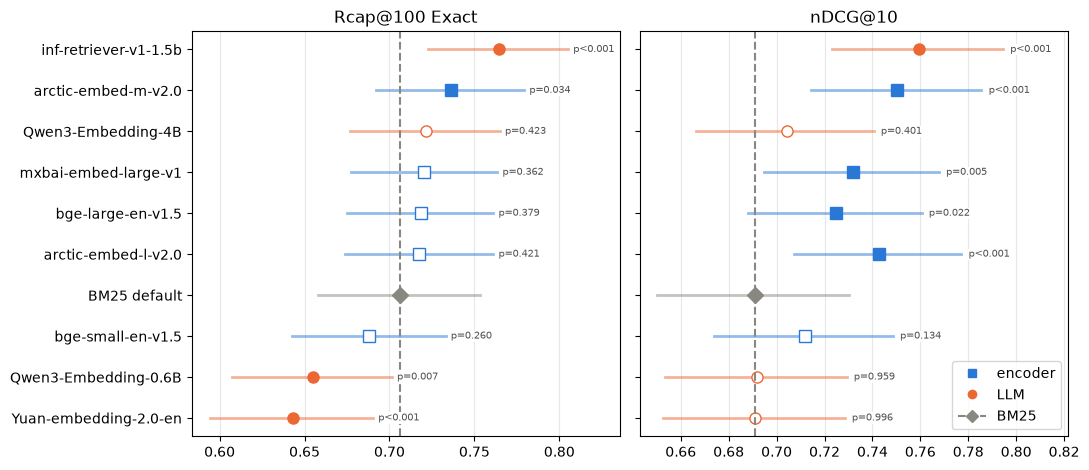

In [5]:
order = sorted(RUNS, key=lambda r: summary[r]["Rcap@100_exact"]["mean"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, metric, title in [
    (axes[0], "Rcap@100_exact", "Rcap@100 Exact"),
    (axes[1], "nDCG@10", "nDCG@10"),
]:
    for y, run in enumerate(order):
        s = summary[run][metric]
        if run == BASELINE:
            colour, marker, filled = "#888780", "D", True
        else:
            group = MODELS[run][1]
            colour, marker = COLOURS[group], MARKERS[group]
            filled = compare(BASELINE, run, metric)[1] < RULE_P
        ax.plot([s["low"], s["high"]], [y, y], color=colour, linewidth=2, alpha=0.5)
        ax.plot(
            s["mean"],
            y,
            marker=marker,
            markersize=8,
            color=colour,
            markerfacecolor=colour if filled else "white",
        )
        if run != BASELINE:
            p = compare(BASELINE, run, metric)[1]
            ax.text(
                s["high"] + 0.003,
                y,
                p_text(p),
                va="center",
                fontsize=7,
                color="#52514e",
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.5},
            )
    ax.axvline(summary[BASELINE][metric]["mean"], color="#888780", linestyle="--")
    ax.set(title=title)
    ax.set_xlim(right=ax.get_xlim()[1] + 0.02)
    ax.grid(axis="x", alpha=0.3)
axes[0].set_yticks(range(len(order)), [LABELS[r] for r in order])
handles = [
    plt.Line2D([], [], marker=MARKERS[g], color=COLOURS[g], linestyle="", label=g)
    for g in COLOURS
] + [plt.Line2D([], [], marker="D", color="#888780", linestyle="--", label="BM25")]
axes[1].legend(handles=handles, loc="lower right")
plt.tight_layout()

## 3. MTEB score vs WANDS score

**The leaderboard did not predict the ranking here.** Hollow marker: reads left to right.

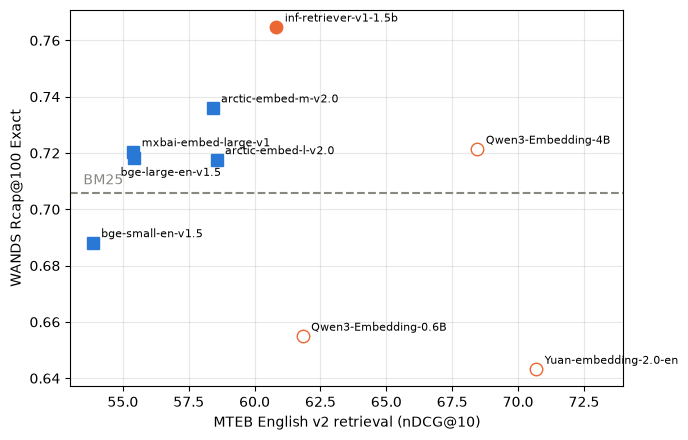

In [6]:
LABEL_OFFSETS = {"dense_bge_large": (-10, -13)}
fig, ax = plt.subplots(figsize=(7, 4.5))
for run, (label, group, _, reads, mteb) in MODELS.items():
    score = summary[run]["Rcap@100_exact"]["mean"]
    ax.plot(
        mteb,
        score,
        marker=MARKERS[group],
        markersize=9,
        color=COLOURS[group],
        markerfacecolor=COLOURS[group] if reads == "both ways" else "white",
    )
    offset = LABEL_OFFSETS.get(run, (6, 4))
    ax.annotate(label, (mteb, score), xytext=offset, textcoords="offset points", fontsize=8)
ax.axhline(summary[BASELINE]["Rcap@100_exact"]["mean"], color="#888780", linestyle="--")
ax.text(53.5, summary[BASELINE]["Rcap@100_exact"]["mean"] + 0.003, "BM25", color="#888780")
ax.set(xlabel="MTEB English v2 retrieval (nDCG@10)", ylabel="WANDS Rcap@100 Exact", xlim=(53, 74))
ax.grid(alpha=0.3)
plt.tight_layout()

## 4. Recall curve

BM25 against the best encoder and the best LLM embedder. **Exact**: only perfect matches count. **Exact + Partial**: right product type with a detail missing also counts. Shaded: 95% interval.

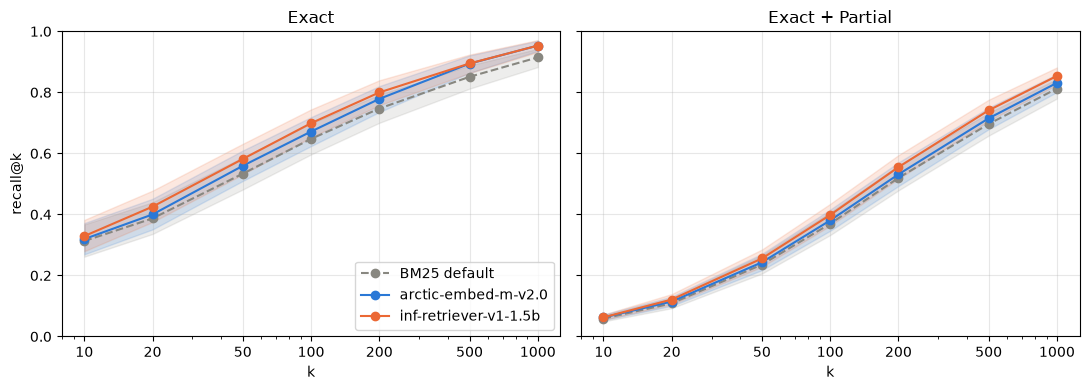

In [7]:
STYLE = {
    BASELINE: {"color": "#888780", "linestyle": "--"},
    "dense_arctic_m": {"color": "#2a78d6", "linestyle": "-"},
    "dense_inf_15b": {"color": "#eb6834", "linestyle": "-"},
}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, level, title in [(axes[0], "exact", "Exact"), (axes[1], "any", "Exact + Partial")]:
    for run, style in STYLE.items():
        stats = [summary[run][f"R@{k}_{level}"] for k in RECALL_KS]
        ax.plot(RECALL_KS, [s["mean"] for s in stats], marker="o", label=LABELS[run], **style)
        low, high = [s["low"] for s in stats], [s["high"] for s in stats]
        ax.fill_between(RECALL_KS, low, high, color=style["color"], alpha=0.15)
    ax.set(xscale="log", xlabel="k", title=title, ylim=(0, 1))
    ax.set_xticks(RECALL_KS, [str(k) for k in RECALL_KS])
    ax.grid(alpha=0.3)
axes[0].set_ylabel("recall@k")
axes[0].legend(loc="lower right")
plt.tight_layout()

## 5. What stands out

The numbers behind each observation; reasons below are **untested ideas**.

In [8]:
checks = [
    ("Size, bge: large vs small", "dense_bge_small", "dense_bge_large", "Rcap@100_exact"),
    ("Size, Qwen3: 4B vs 0.6B", "dense_qwen3_06b", "dense_qwen3_4b", "Rcap@100_exact"),
    ("Size, arctic: l vs m", "dense_arctic_m", "dense_arctic_l", "Rcap@100_exact"),
    ("inf-retriever vs BM25, Exact", BASELINE, "dense_inf_15b", "Rcap@100_exact"),
    ("inf-retriever vs BM25, Exact + Partial", BASELINE, "dense_inf_15b", "Rcap@100_any"),
    ("arctic-m vs BM25, Exact", BASELINE, "dense_arctic_m", "Rcap@100_exact"),
    ("arctic-m vs BM25, Exact + Partial", BASELINE, "dense_arctic_m", "Rcap@100_any"),
    ("Qwen3-4B vs BM25, top 10 Exact", BASELINE, "dense_qwen3_4b", "R@10_exact"),
]
display(
    pd.DataFrame(
        [(name, metric, *compare(a, b, metric)) for name, a, b, metric in checks],
        columns=["comparison", "metric", "Δ", "p"],
    ).set_index("comparison")
)

,metric,Δ,p
comparison,,,
"Size, bge: large vs small",Rcap@100_exact,3.0,0.006
"Size, Qwen3: 4B vs 0.6B",Rcap@100_exact,6.6,0.000
"Size, arctic: l vs m",Rcap@100_exact,-1.8,0.016
"inf-retriever vs BM25, Exact",Rcap@100_exact,5.9,0.000
"inf-retriever vs BM25, Exact + Partial",Rcap@100_any,6.7,0.000
"arctic-m vs BM25, Exact",Rcap@100_exact,3.0,0.034
"arctic-m vs BM25, Exact + Partial",Rcap@100_any,4.3,0.000
"Qwen3-4B vs BM25, top 10 Exact",R@10_exact,-5.5,0.001


The same significance counts (p < 0.05 vs BM25), grouped by how the model reads the text.

In [9]:
direction = []
for reads in ["both ways", "left to right"]:
    runs = [run for run, m in MODELS.items() if m[3] == reads]
    row = {"reads text": reads, "models": len(runs)}
    for metric, name in [("Rcap@100_exact", "Rcap@100"), ("nDCG@10", "nDCG@10")]:
        tests = [compare(BASELINE, run, metric) for run in runs]
        better = sum(d > 0 and p < RULE_P for d, p in tests)
        worse = sum(d < 0 and p < RULE_P for d, p in tests)
        row[f"{name} better / worse"] = f"{better} / {worse}"
    direction.append(row)
display(pd.DataFrame(direction).set_index("reads text"))

,models,Rcap@100 better / worse,nDCG@10 better / worse
reads text,,,
both ways,6,2 / 0,5 / 0
left to right,3,0 / 2,0 / 0


- **MTEB rank did not carry over.** Yuan is first on MTEB retrieval and last here. MTEB retrieval is mostly question answering and scientific text; WANDS is 2–4 keywords against product listings.
- **Left-to-right LLMs do worst; the models that read both ways are never worse than BM25**, and 5 of 6 have a better top 10. inf-retriever, an LLM converted to read both ways, is best on both metrics. Possible reasons: a left-to-right model builds its vector from the last token, so a three-word query after a long instruction may be dominated by the instruction; and Qwen3's instruction asks for "passages that answer the query", which fits questions, not "blue velvet sofa".
- **But reading direction is confounded.** The three left-to-right models are one family (Yuan is a Qwen3-0.6B fine-tune) and share the base model, the instruction and last-token pooling, so this is one family against five. Tests that would separate the causes:

| Test | Isolates |
|---|---|
| pplx-embed-v1-0.6b: Qwen3 converted to read both ways | reading direction |
| Qwen3 with a product instruction ("Given a product search query, retrieve matching products") | the instruction |
| harrier-oss-v1-0.6b: Qwen3, left to right, different training | the training recipe |

- **Size helps inside a family, not across.** bge and Qwen3 gain from size, but arctic-m (305M) beats arctic-l (568M). The training recipe matters more than parameter count.
- **Dense finds the right product type more than the exact product.** Every model gains more when Partial matches count, and Qwen3-4B's top 10 has fewer Exact matches than BM25. Embeddings seem to capture *what kind* of product; word matching captures colour, size and material.
- **The two best models come from different families** (an LLM that reads both ways, a small encoder), and both differ from BM25: candidates to combine.

## 6. Cost

Tower (RTX 4070), background apps closed. Latency: one query at a time, embedding plus search over 43k products.

In [10]:
cost_rows = {}
for run in RUNS:
    c = meta[run]["cost"]
    cost_rows[LABELS[run]] = {
        "indexing (s)": c["indexing_seconds"],
        "index (MB)": c["index_size_mb"],
        "p50 (ms)": c["latency"]["p50_ms"],
        "p99 (ms)": c["latency"]["p99_ms"],
        "peak GPU (GB)": c.get("peak_gpu_gb"),
    }
display(pd.DataFrame(cost_rows).T.round(1))

,indexing (s),index (MB),p50 (ms),p99 (ms),peak GPU (GB)
BM25 default,2.2,16.2,0.7,1.3,NaN
bge-small-en-v1.5,25.4,66.0,6.8,8.1,0.8
bge-large-en-v1.5,257.7,176.1,12.2,14.2,2.2
mxbai-embed-large-v1,259.1,176.1,12.2,13.9,2.2
arctic-embed-m-v2.0,131.2,132.1,8.8,9.7,2.1
arctic-embed-l-v2.0,321.1,176.1,12.5,15.1,3.1
Qwen3-Embedding-0.6B,191.0,176.1,30.4,33.9,3.6
Yuan-embedding-2.0-en,186.3,176.1,28.9,32.7,1.7
inf-retriever-v1-1.5b,332.9,264.2,24.5,27.6,5.6
Qwen3-Embedding-4B,915.8,440.3,39.7,44.9,9.2
